<a href="https://colab.research.google.com/github/mn660875/Navttc-Challenges/blob/main/Week7_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NAVTTC AI (ML & DL) - Week 7 Assignment
**Module:** Deep Learning I (Boosting, MLP, Feed Forward NN, CNN)
**Tasks (Annexure-I):** 56 to 64

Run in Google Colab. For Task 64 (CIFAR-10) use **Runtime > Change runtime type > T4 GPU**.


## Task 56 - Demonstration of Neural Networks (from scratch with NumPy)
We build a tiny neural network (2 inputs, 4 hidden neurons, 1 output) and teach it the XOR problem.
Steps: forward pass, loss, backward pass (backpropagation), update weights.

Epoch 0, Loss: 0.2832
Epoch 2000, Loss: 0.0028
Epoch 4000, Loss: 0.0008
Epoch 6000, Loss: 0.0004
Epoch 8000, Loss: 0.0003

Predictions (rounded):
[0 1 1 0] <- predicted
[0 1 1 0] <- expected


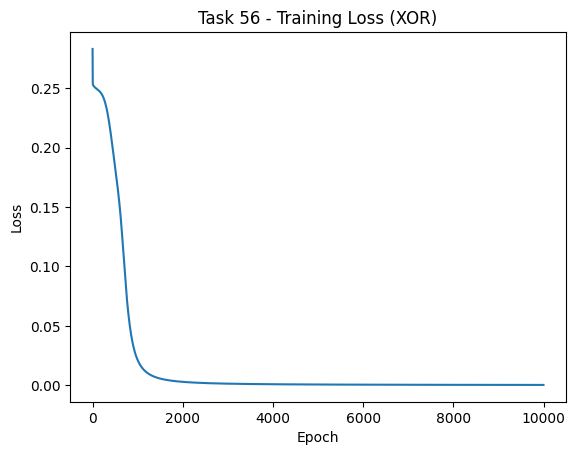

In [2]:
import numpy as np

# Step 1: XOR data (inputs and expected outputs)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])

# Step 2: Activation function (sigmoid) and its derivative
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(a):
    # 'a' is already sigmoid(z)
    return a * (1 - a)

# Step 3: Initialise weights randomly, biases with zeros
np.random.seed(42)
W1 = np.random.randn(2, 4)   # input -> hidden
b1 = np.zeros((1, 4))
W2 = np.random.randn(4, 1)   # hidden -> output
b2 = np.zeros((1, 1))

learning_rate = 0.5
losses = []

# Step 4: Training loop
for epoch in range(10000):
    # ---- Forward pass ----
    z1 = X @ W1 + b1
    a1 = sigmoid(z1)          # hidden layer output
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)          # final prediction

    # ---- Loss (Mean Squared Error) ----
    loss = np.mean((y - a2) ** 2)
    losses.append(loss)

    # ---- Backward pass (backpropagation) ----
    d_a2 = (a2 - y) * sigmoid_derivative(a2)        # error at output
    d_W2 = a1.T @ d_a2
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = (d_a2 @ W2.T) * sigmoid_derivative(a1)   # error sent back to hidden layer
    d_W1 = X.T @ d_a1
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # ---- Update weights ----
    W2 -= learning_rate * d_W2
    b2 -= learning_rate * d_b2
    W1 -= learning_rate * d_W1
    b1 -= learning_rate * d_b1

    if epoch % 2000 == 0:
        print(f"Epoch {epoch}, Loss: {loss:.4f}")

# Step 5: Check predictions
print("\nPredictions (rounded):")
print(np.round(a2).astype(int).ravel(), "<- predicted")
print(y.ravel(), "<- expected")

# Step 6: Plot loss curve
import matplotlib.pyplot as plt
plt.plot(losses)
plt.title("Task 56 - Training Loss (XOR)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

## Task 57 - Exercise on MLP (Multi-Layer Perceptron)
We use Keras to build an MLP that classifies breast cancer (malignant or benign).

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

Test Accuracy: 0.9825


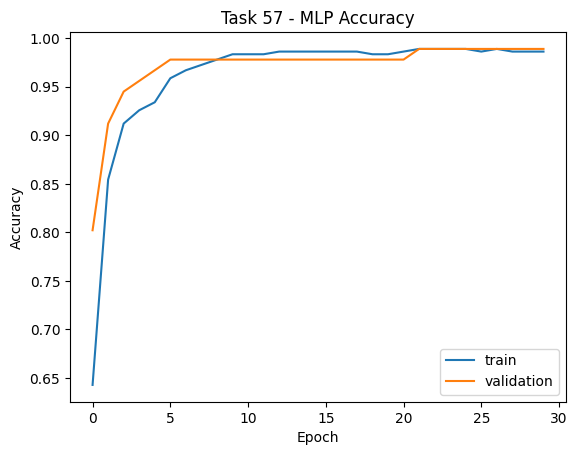

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

# Step 1: Load dataset (569 samples, 30 features)
data = load_breast_cancer()
X, y = data.data, data.target

# Step 2: Split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 3: Scale features (neural networks like small numbers)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 4: Build the MLP (input -> 16 -> 8 -> 1)
model = keras.Sequential([
    layers.Input(shape=(30,)),
    layers.Dense(16, activation="relu"),    # hidden layer 1
    layers.Dense(8, activation="relu"),     # hidden layer 2
    layers.Dense(1, activation="sigmoid")   # output: probability of class 1
])

# Step 5: Compile (loss + optimizer + metric)
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

# Step 6: Train
history = model.fit(X_train, y_train, epochs=30, batch_size=16,
                    validation_split=0.2, verbose=0)

# Step 7: Evaluate on test data
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {acc:.4f}")

# Step 8: Plot accuracy
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Task 57 - MLP Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

## Task 58 - Exercise on Feed Forward Neural Network
First we do one forward pass by hand with NumPy (to see how data flows), then we train a Keras feed forward network on the Iris dataset (3 classes).

Hidden layer output: [[0.31 0.7  0.73]]
Final output: [[0.815176]]

Test Accuracy: 0.9333
Predicted class: versicolor
Actual class   : versicolor


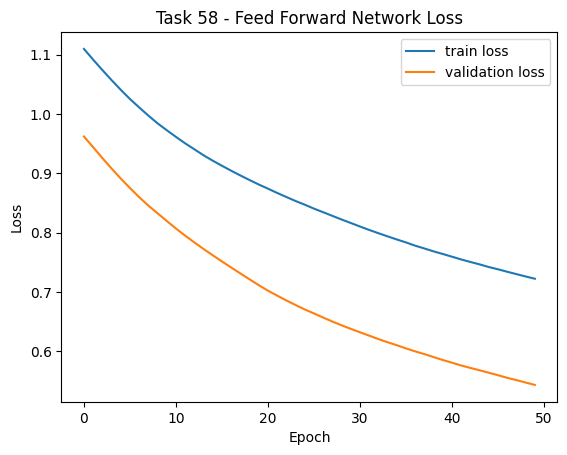

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

# ---------- Part A: One forward pass by hand ----------
x = np.array([[0.5, 0.8]])                 # one input with 2 features
W1 = np.array([[0.1, 0.4, 0.3],
               [0.2, 0.5, 0.6]])           # 2 inputs -> 3 hidden neurons
b1 = np.array([[0.1, 0.1, 0.1]])
W2 = np.array([[0.7], [0.8], [0.9]])       # 3 hidden -> 1 output
b2 = np.array([[0.05]])

hidden = np.maximum(0, x @ W1 + b1)        # ReLU activation
output = 1 / (1 + np.exp(-(hidden @ W2 + b2)))   # sigmoid activation
print("Hidden layer output:", hidden)
print("Final output:", output)

# ---------- Part B: Feed forward network on Iris ----------
iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = keras.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(10, activation="relu"),
    layers.Dense(10, activation="relu"),
    layers.Dense(3, activation="softmax")   # 3 classes -> softmax
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(X_train, y_train, epochs=50, validation_split=0.2, verbose=0)

loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {acc:.4f}")

# Predict one sample
sample = X_test[0].reshape(1, -1)
pred = np.argmax(model.predict(sample, verbose=0))
print("Predicted class:", iris.target_names[pred])
print("Actual class   :", iris.target_names[y_test[0]])

plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.title("Task 58 - Feed Forward Network Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

## Task 59 - Exercise on Neural Network Loss Functions
We write the common loss functions ourselves with NumPy and compare them on small examples.
- Regression: MSE, MAE, Huber
- Classification: Binary Cross-Entropy, Categorical Cross-Entropy, Hinge

In [5]:
import numpy as np

# ---------------- Regression losses ----------------
y_true = np.array([3.0, 5.0, 2.5, 7.0])
y_pred = np.array([2.5, 5.0, 4.0, 8.0])

def mse(y_true, y_pred):
    # Mean Squared Error: average of squared differences
    return np.mean((y_true - y_pred) ** 2)

def mae(y_true, y_pred):
    # Mean Absolute Error: average of absolute differences
    return np.mean(np.abs(y_true - y_pred))

def huber(y_true, y_pred, delta=1.0):
    # Huber loss: squared for small errors, linear for big errors
    error = y_true - y_pred
    is_small = np.abs(error) <= delta
    squared = 0.5 * error ** 2
    linear = delta * (np.abs(error) - 0.5 * delta)
    return np.mean(np.where(is_small, squared, linear))

print("--- Regression ---")
print("MSE   :", mse(y_true, y_pred))
print("MAE   :", mae(y_true, y_pred))
print("Huber :", huber(y_true, y_pred))

# ---------------- Classification losses ----------------
def binary_cross_entropy(y_true, y_prob):
    eps = 1e-12                                  # avoid log(0)
    y_prob = np.clip(y_prob, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob))

def categorical_cross_entropy(y_true_onehot, y_prob):
    eps = 1e-12
    y_prob = np.clip(y_prob, eps, 1.0)
    return -np.mean(np.sum(y_true_onehot * np.log(y_prob), axis=1))

def hinge(y_true, scores):
    # y_true must be -1 or +1
    return np.mean(np.maximum(0, 1 - y_true * scores))

# Binary example
yb_true = np.array([1, 0, 1, 1])
yb_prob = np.array([0.9, 0.2, 0.7, 0.4])

# Multi-class example (3 classes, one-hot labels)
yc_true = np.array([[1, 0, 0],
                    [0, 1, 0],
                    [0, 0, 1]])
yc_prob = np.array([[0.7, 0.2, 0.1],
                    [0.1, 0.8, 0.1],
                    [0.2, 0.3, 0.5]])

# Hinge example (labels -1 / +1)
yh_true = np.array([1, -1, 1, -1])
yh_scores = np.array([0.8, -0.5, -0.3, 0.4])

print("\n--- Classification ---")
print("Binary Cross-Entropy      :", binary_cross_entropy(yb_true, yb_prob))
print("Categorical Cross-Entropy :", categorical_cross_entropy(yc_true, yc_prob))
print("Hinge Loss                :", hinge(yh_true, yh_scores))

# ---------------- Compare with Keras ----------------
from tensorflow import keras
print("\n--- Same results with Keras (to verify) ---")
print("Keras MSE :", keras.losses.MeanSquaredError()(y_true, y_pred).numpy())
print("Keras BCE :", keras.losses.BinaryCrossentropy()(yb_true, yb_prob).numpy())
print("Keras CCE :", keras.losses.CategoricalCrossentropy()(yc_true, yc_prob).numpy())

--- Regression ---
MSE   : 0.875
MAE   : 0.75
Huber : 0.40625

--- Classification ---
Binary Cross-Entropy      : 0.4003674356962309
Categorical Cross-Entropy : 0.4243218919376292
Hinge Loss                : 0.85

--- Same results with Keras (to verify) ---
Keras MSE : 0.875
Keras BCE : 0.40036744
Keras CCE : 0.4243219


## Task 60 - Linguistics using Machine Learning in Python (NLP Introduction)
Basic NLP steps with NLTK: tokenization, POS tagging, Named Entity Recognition (NER).

In [6]:
import nltk

# Download the required NLTK data (runs once)
for pkg in ["punkt", "punkt_tab", "averaged_perceptron_tagger",
            "averaged_perceptron_tagger_eng", "maxent_ne_chunker",
            "maxent_ne_chunker_tab", "words"]:
    nltk.download(pkg, quiet=True)

text = "Elon Musk founded SpaceX in California. Google is a big company in the USA."

# Step 1: Sentence tokenization (split text into sentences)
sentences = nltk.sent_tokenize(text)
print("Sentences:", sentences)

# Step 2: Word tokenization (split text into words)
words = nltk.word_tokenize(text)
print("\nWords:", words)

# Step 3: POS tagging (noun, verb, adjective, etc.)
pos_tags = nltk.pos_tag(words)
print("\nPOS Tags:")
for word, tag in pos_tags:
    print(f"{word:12} -> {tag}")

# Step 4: Named Entity Recognition (find people, places, organizations)
tree = nltk.ne_chunk(pos_tags)
print("\nNamed Entities:")
for subtree in tree:
    if hasattr(subtree, "label"):
        entity = " ".join(token for token, tag in subtree.leaves())
        print(f"{entity:12} -> {subtree.label()}")

Sentences: ['Elon Musk founded SpaceX in California.', 'Google is a big company in the USA.']

Words: ['Elon', 'Musk', 'founded', 'SpaceX', 'in', 'California', '.', 'Google', 'is', 'a', 'big', 'company', 'in', 'the', 'USA', '.']

POS Tags:
Elon         -> NNP
Musk         -> NNP
founded      -> VBD
SpaceX       -> NNP
in           -> IN
California   -> NNP
.            -> .
Google       -> NNP
is           -> VBZ
a            -> DT
big          -> JJ
company      -> NN
in           -> IN
the          -> DT
USA          -> NNP
.            -> .

Named Entities:
Elon         -> PERSON
Musk         -> PERSON
SpaceX       -> ORGANIZATION
California   -> GPE
Google       -> PERSON
USA          -> ORGANIZATION


## Task 61 - Text Processing (NLTK)
Cleaning raw text: lowercase, remove punctuation, stopwords, stemming and lemmatization.

In [7]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

text = "The children are playing in the gardens, and they were running faster than the dogs!!!"

# Step 1: Lowercase
text_lower = text.lower()
print("1. Lowercase  :", text_lower)

# Step 2: Remove punctuation (keep only letters and spaces)
text_clean = re.sub(r"[^a-z\s]", "", text_lower)
print("2. No punct.  :", text_clean)

# Step 3: Tokenize
tokens = word_tokenize(text_clean)
print("3. Tokens     :", tokens)

# Step 4: Remove stopwords (the, are, in, and ...)
stop_words = set(stopwords.words("english"))
filtered = [w for w in tokens if w not in stop_words]
print("4. No stopwords:", filtered)

# Step 5: Stemming (cut word to its root, may not be a real word)
stemmer = PorterStemmer()
stems = [stemmer.stem(w) for w in filtered]
print("5. Stemmed    :", stems)

# Step 6: Lemmatization (real dictionary root word)
lemmatizer = WordNetLemmatizer()
lemmas = [lemmatizer.lemmatize(w, pos="v") for w in filtered]
print("6. Lemmatized :", lemmas)

# Step 7: Word frequency
from nltk import FreqDist
freq = FreqDist(filtered)
print("\nMost common words:", freq.most_common(5))

1. Lowercase  : the children are playing in the gardens, and they were running faster than the dogs!!!
2. No punct.  : the children are playing in the gardens and they were running faster than the dogs
3. Tokens     : ['the', 'children', 'are', 'playing', 'in', 'the', 'gardens', 'and', 'they', 'were', 'running', 'faster', 'than', 'the', 'dogs']
4. No stopwords: ['children', 'playing', 'gardens', 'running', 'faster', 'dogs']
5. Stemmed    : ['children', 'play', 'garden', 'run', 'faster', 'dog']
6. Lemmatized : ['children', 'play', 'garden', 'run', 'faster', 'dog']

Most common words: [('children', 1), ('playing', 1), ('gardens', 1), ('running', 1), ('faster', 1)]


## Task 62 - Text Analysis
Word frequency, Bag of Words (BoW), TF-IDF, document similarity, and a small sentiment classifier.

Top words: [('and', 5), ('this', 3), ('is', 3), ('great', 3), ('i', 2), ('movie', 2), ('it', 2), ('amazing', 2)]


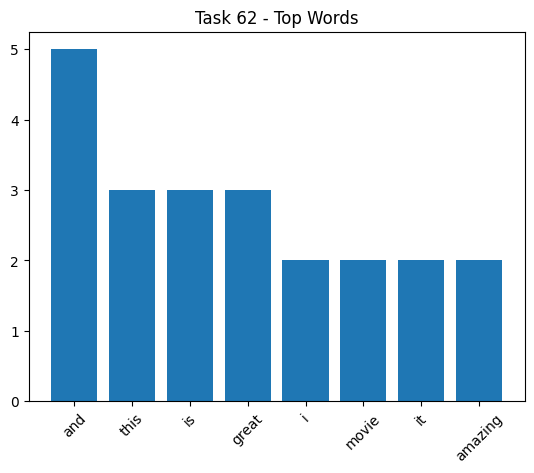


Bag of Words table:
   acting  amazing  and  awful  boring  film  great  hate  is  it  love  \
0       0        1    1      0       0     0      1     0   1   1     1   
1       0        0    1      0       1     0      0     0   1   0     0   
2       0        1    1      0       0     1      0     0   0   0     0   
3       0        0    0      1       0     1      0     1   1   1     0   
4       1        0    1      0       0     0      2     0   0   0     0   
5       1        0    1      0       1     0      0     0   0   0     0   

   movie  story  terrible  this  what  wonderful  
0      1      0         0     1     0          0  
1      1      0         1     1     0          0  
2      0      0         0     0     1          1  
3      0      0         0     1     0          0  
4      0      1         0     0     0          0  
5      0      1         1     0     0          0  

TF-IDF table (rounded):
   acting  amazing   and  awful  boring  film  great  hate    is    it 

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.naive_bayes import MultinomialNB

# Small set of documents (reviews)
docs = [
    "I love this movie, it is great and amazing",
    "This movie is terrible and boring",
    "What a wonderful and amazing film",
    "I hate this film, it is awful",
    "Great acting and a great story",
    "Boring story and terrible acting",
]
labels = [1, 0, 1, 0, 1, 0]   # 1 = positive, 0 = negative

# ---- Step 1: Word frequency ----
all_words = " ".join(docs).lower().replace(",", "").split()
freq = Counter(all_words).most_common(8)
print("Top words:", freq)

words, counts = zip(*freq)
plt.bar(words, counts)
plt.title("Task 62 - Top Words")
plt.xticks(rotation=45)
plt.show()

# ---- Step 2: Bag of Words ----
bow = CountVectorizer()
bow_matrix = bow.fit_transform(docs)
print("\nBag of Words table:")
print(pd.DataFrame(bow_matrix.toarray(), columns=bow.get_feature_names_out()))

# ---- Step 3: TF-IDF ----
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(docs)
print("\nTF-IDF table (rounded):")
print(pd.DataFrame(tfidf_matrix.toarray().round(2), columns=tfidf.get_feature_names_out()))

# ---- Step 4: Document similarity (cosine) ----
sim = cosine_similarity(tfidf_matrix)
print("\nSimilarity between doc 0 and doc 2:", round(sim[0][2], 3))
print("Similarity between doc 0 and doc 1:", round(sim[0][1], 3))

# ---- Step 5: Simple sentiment classifier ----
model = MultinomialNB()
model.fit(bow_matrix, labels)

new_reviews = ["This is a great movie", "What an awful and boring film"]
new_bow = bow.transform(new_reviews)
predictions = model.predict(new_bow)
for review, p in zip(new_reviews, predictions):
    print(f"'{review}' -> {'Positive' if p == 1 else 'Negative'}")

## Task 63 - Demonstrate Convolutional Neural Network (CNN)
Part A: see how a convolution filter works (edge detection) with NumPy.
Part B: train a small CNN on MNIST (handwritten digits).

Convolution output:
 [[ 0. 27. 27.  0.]
 [ 0. 27. 27.  0.]
 [ 0. 27. 27.  0.]
 [ 0. 27. 27.  0.]]


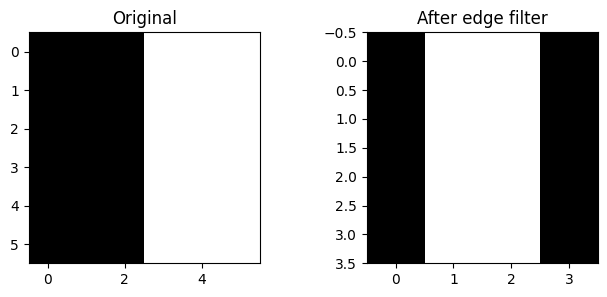

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - accuracy: 0.9094 - loss: 0.3162 - val_accuracy: 0.9778 - val_loss: 0.0828
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 48ms/step - accuracy: 0.9760 - loss: 0.0794 - val_accuracy: 0.9815 - val_loss: 0.0651
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 50ms/step - accuracy: 0.9827 - loss: 0.0575 - val_accuracy: 0.9830 - val_loss: 0.0610

Test Accuracy: 0.9818


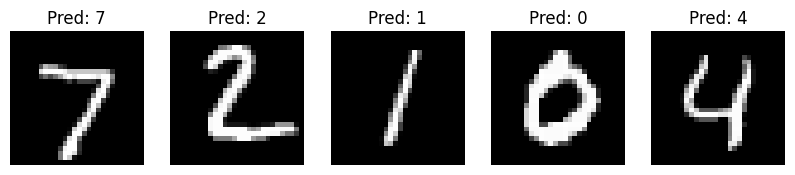

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

# ---------- Part A: What does a convolution do? ----------
# A simple 6x6 image: left half dark (0), right half bright (9)
image = np.array([[0, 0, 0, 9, 9, 9]] * 6)

# Vertical edge detection filter (kernel)
kernel = np.array([[-1, 0, 1],
                   [-1, 0, 1],
                   [-1, 0, 1]])

def convolve2d(img, k):
    h, w = img.shape
    kh, kw = k.shape
    out = np.zeros((h - kh + 1, w - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            patch = img[i:i + kh, j:j + kw]     # take a small part of the image
            out[i, j] = np.sum(patch * k)       # multiply and add
    return out

result = convolve2d(image, kernel)
print("Convolution output:\n", result)

fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].imshow(image, cmap="gray"); ax[0].set_title("Original")
ax[1].imshow(result, cmap="gray"); ax[1].set_title("After edge filter")
plt.show()

# ---------- Part B: CNN on MNIST ----------
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixels (0-255 -> 0-1) and add channel dimension
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
X_train = X_train[..., np.newaxis]   # shape (60000, 28, 28, 1)
X_test = X_test[..., np.newaxis]

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, (3, 3), activation="relu"),   # find simple patterns
    layers.MaxPooling2D((2, 2)),                    # shrink the image
    layers.Conv2D(32, (3, 3), activation="relu"),   # find complex patterns
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),                               # 2D -> 1D
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")          # 10 digits (0-9)
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

history = model.fit(X_train, y_train, epochs=3, batch_size=128,
                    validation_split=0.1, verbose=1)

loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {acc:.4f}")

# Show 5 predictions
preds = np.argmax(model.predict(X_test[:5], verbose=0), axis=1)
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")
    plt.title(f"Pred: {preds[i]}")
    plt.axis("off")
plt.show()

## Task 64 - Perform CNN on CIFAR-10 Dataset
CIFAR-10 has 60,000 colour images (32x32) in 10 classes (airplane, car, bird, cat, ...).
Use a GPU runtime for faster training.

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 26s 0us/step
Train shape: (50000, 32, 32, 3)  Test shape: (10000, 32, 32, 3)


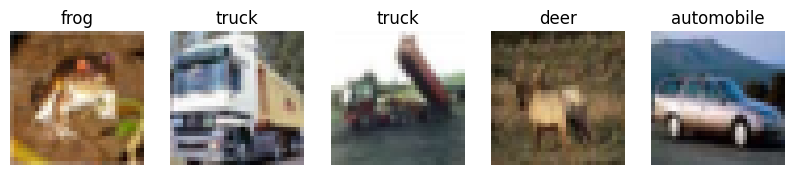

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 94s 131ms/step - accuracy: 0.3994 - loss: 1.6404 - val_accuracy: 0.5264 - val_loss: 1.3038
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 92s 131ms/step - accuracy: 0.5511 - loss: 1.2559 - val_accuracy: 0.6314 - val_loss: 1.0274
Epoch 3/10
441/704 ━━━━━━━━━━━━━━━━━━━━ 35s 134ms/step - accuracy: 0.6041 - loss: 1.1112

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

# Step 1: Load dataset
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

# Step 2: Look at some images
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis("off")
plt.show()

# Step 3: Normalize pixel values (0-255 -> 0-1)
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Step 4: Build the CNN
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),                      # reduce overfitting
    layers.Dense(10, activation="softmax")
])

# Step 5: Compile
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

# Step 6: Train
history = model.fit(X_train, y_train, epochs=10, batch_size=64,
                    validation_split=0.1, verbose=1)

# Step 7: Evaluate
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_acc:.4f}")

# Step 8: Plot accuracy and loss
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
plt.show()

# Step 9: Predictions on 5 test images
preds = np.argmax(model.predict(X_test[:5], verbose=0), axis=1)
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[i])
    plt.title(f"P: {class_names[preds[i]]}\nA: {class_names[y_test[i][0]]}", fontsize=8)
    plt.axis("off")
plt.show()